# Chapitre 10 - Cours 2 : Routeur, passerelle, caches et motifs agentiques

Nous poursuivons la construction de l'architecture commencée au cours 1 (contexte et
garde-fous). L'application ÉlectroNova va maintenant apprendre à **orienter** les requêtes
(routeur d'intention), à **parler à plusieurs modèles** de façon sûre et résiliente
(passerelle), à **ne pas recalculer** ce qu'elle sait déjà (caches), à **boucler** quand une
première réponse ne suffit pas et enfin à **agir** (actions d'écriture).

Sections du livre couvertes : *Step 3. Add Model Router and Gateway* (*Router*, *Gateway*),
*Step 4. Reduce Latency with Caches* (*Exact caching*, *Semantic caching*),
*Step 5. Add Agent Patterns*.

Plan :
1. étape 3a : le routeur d'intention ;
2. étape 3b : la passerelle de modèles ;
3. étape 4a : le cache exact ;
4. étape 4b : le cache sémantique ;
5. étape 5 : les motifs agentiques ;
6. étape 6 : les actions d'écriture.

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
qwen = lambda messages: llm.chat(messages, model_id=llm.SMALL, max_new_tokens=80)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)      # MiniLM multilingue
embed_en = lambda texts: llm.embed(texts, llm.EMBED)         # MiniLM entraîné sur l'anglais

## 1. Étape 3a : le routeur d'intention (section *Router*)

**Le problème.** Utiliser un seul modèle pour toutes les requêtes est rarement optimal.
Certaines demandes ont une réponse toute faite (réinitialiser un mot de passe), d'autres
doivent aller à un humain (litige de facturation), d'autres à un modèle spécialisé
(dépannage technique), et certaines sont hors périmètre (« pour qui vas-tu voter ? »). Un
**routeur** prédit l'intention de l'utilisateur et envoie la requête à la bonne solution.
Deux bénéfices : la **spécialisation** (meilleure qualité) et les **économies** (les
requêtes simples vont vers des solutions bon marché).

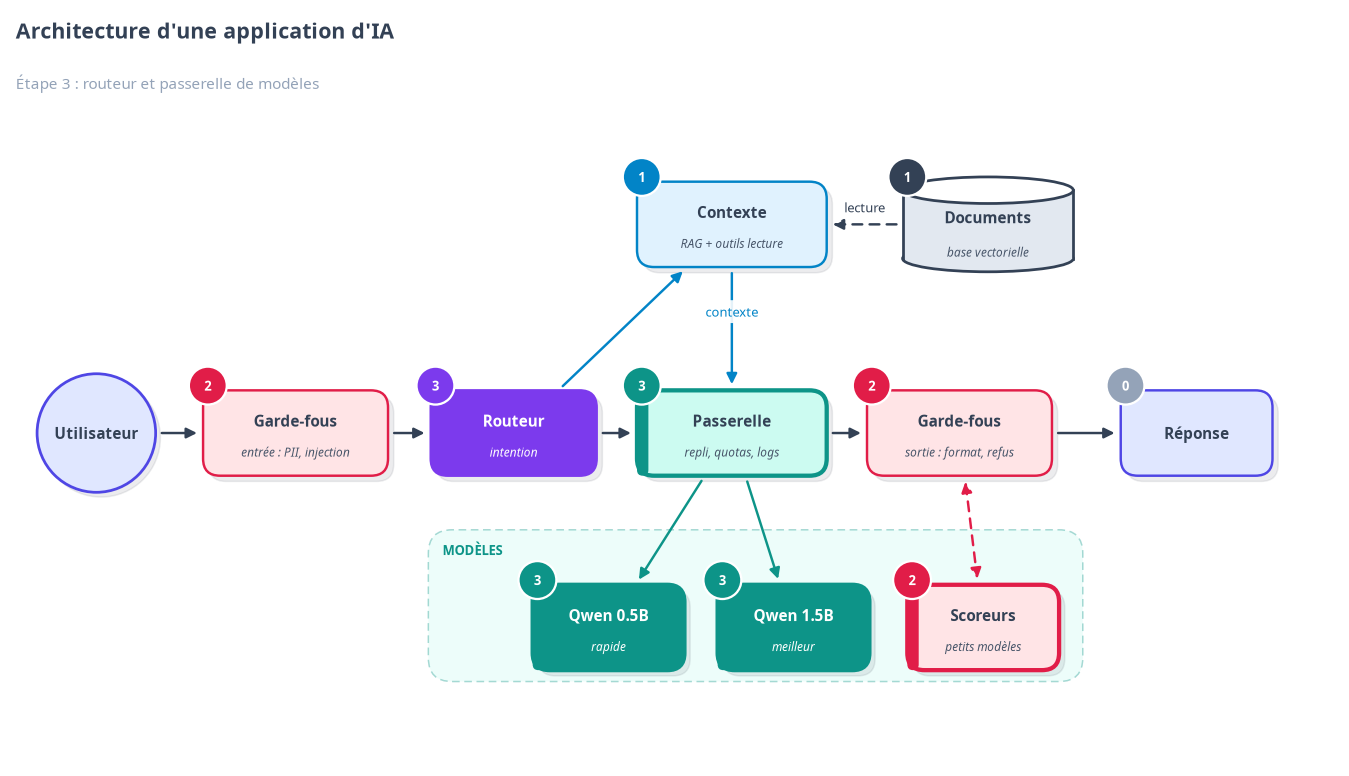

In [2]:
A.architecture_diagram(3);

Notre routeur est un classifieur d'intention sur 5 classes, entraîné sur 10 exemples
rédigés à la main par classe (`A.INTENTS_TRAIN`), et testé sur 20 phrases différentes
(`A.INTENTS_TEST`). Le tableau rappelle où part chaque intention.

In [3]:
pd.DataFrame([{"intention": k, "exemple": v[0], "destination": A.ROUTES[k]} for k, v in A.INTENTS_TRAIN.items()])

,intention,exemple,destination
0,mot_de_passe,J'ai oublié mon mot de passe,page FAQ
1,facturation,J'ai été débité deux fois,opérateur humain
2,technique,Mon casque Bluetooth ne s'appaire pas,chatbot dépannage (LLM + RAG)
3,commande,Où en est ma commande ?,agent commandes (outils)
4,hors_perimetre,Pour qui vas-tu voter aux prochaines élections ?,réponse type polie


**Le classifieur.** On encode chaque phrase avec un modèle d'embeddings (MiniLM) puis on
compare la requête à chaque intention. Deux variantes :
- **centroïde** : on moyenne les embeddings des exemples de chaque intention $c$,
  $\mu_c = \frac{1}{n_c}\sum_{i : y_i = c} e_i$, et on prédit
  $\hat y = \arg\max_c \cos(e_q, \mu_c)$ ;
- **$k$ plus proches voisins** : le score d'une intention est la similarité moyenne des
  $k$ exemples de cette intention les plus proches de la requête.

Aucun entraînement de réseau : il suffit d'un modèle d'embeddings et de quelques exemples
par classe. C'est ce qui rend le routeur **rapide et bon marché**, une exigence du livre
puisqu'on peut enchaîner plusieurs routeurs. Visualisons les embeddings projetés en 2D.

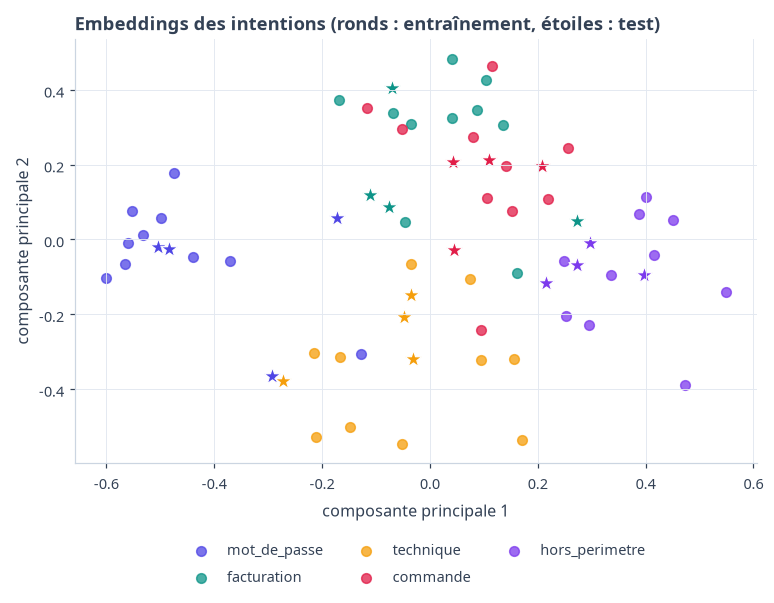

In [4]:
labels = list(A.INTENTS_TRAIN)
train_txt = [t for l in labels for t in A.INTENTS_TRAIN[l]]
train_y = [l for l in labels for _ in A.INTENTS_TRAIN[l]]
test_txt = [t for t, _ in A.INTENTS_TEST]; test_y = [l for _, l in A.INTENTS_TEST]
E_tr, E_te = embed(train_txt), embed(test_txt)
pca = PCA(2, random_state=0).fit(E_tr)
P_tr, P_te = pca.transform(E_tr), pca.transform(E_te)
fig, ax = plt.subplots(figsize=(8, 5))
for l, c in zip(labels, COLORS):
    m = np.array(train_y) == l
    ax.scatter(*P_tr[m].T, color=c, s=40, alpha=0.75, label=l)
    mt = np.array(test_y) == l
    ax.scatter(*P_te[mt].T, color=c, s=140, marker="*", edgecolor="white", linewidth=0.8)
ax.set(xlabel="composante principale 1", ylabel="composante principale 2",
       title="Embeddings des intentions (ronds : entraînement, étoiles : test)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()

Les intentions forment des nuages assez séparés, même en 2 dimensions (sur 384). Comparons
trois encodeurs : le MiniLM **multilingue**, le MiniLM **anglais** (`all-MiniLM-L6-v2`) et
notre embedding lexical `hash_embed` (sac de trigrammes de caractères, sans aucune
sémantique).

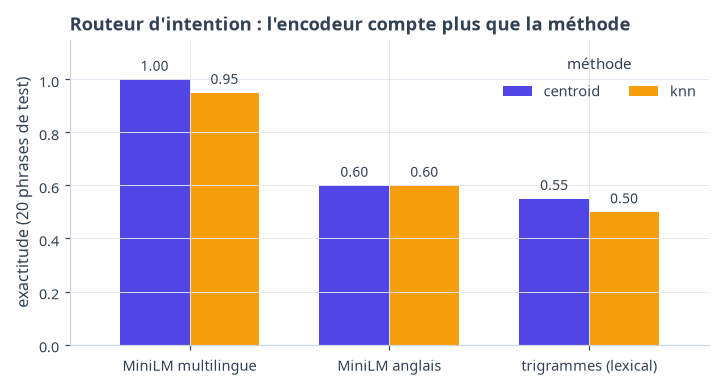

In [5]:
encodeurs = {"MiniLM multilingue": embed, "MiniLM anglais": embed_en, "trigrammes (lexical)": A.hash_embed}
rows, routers = [], {}
for name, f in encodeurs.items():
    for method in ["centroid", "knn"]:
        r = A.IntentRouter(f, method=method, k=3).fit(A.INTENTS_TRAIN)
        routers[(name, method)] = r
        acc = np.mean(np.array(r.predict(test_txt)) == np.array(test_y))
        rows.append({"encodeur": name, "méthode": method, "exactitude": acc})
acc = pd.DataFrame(rows).pivot(index="encodeur", columns="méthode", values="exactitude").loc[list(encodeurs)]
ax = acc.plot.bar(color=[INDIGO, AMBER], figsize=(7.5, 3.6), rot=0, width=0.7)
annotate_bars(ax, "{:.2f}")
ax.set(ylabel="exactitude (20 phrases de test)", xlabel="", ylim=(0, 1.15),
       title="Routeur d'intention : l'encodeur compte plus que la méthode")
ax.legend(title="méthode", ncol=2); plt.show()

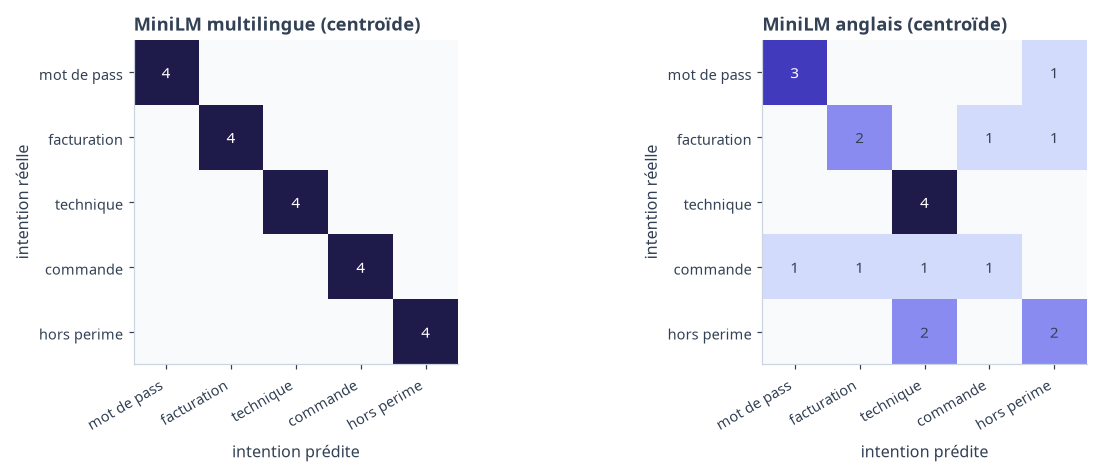

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, name in zip(axes, ["MiniLM multilingue", "MiniLM anglais"]):
    pred = routers[(name, "centroid")].predict(test_txt)
    cm = confusion_matrix(test_y, pred, labels=labels)
    ax.imshow(cm, cmap="aie_seq"); ax.grid(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 2 else SLATE)
    short = [l.replace("_", " ")[:11] for l in labels]
    ax.set_xticks(range(5), short, rotation=30, ha="right"); ax.set_yticks(range(5), short)
    ax.set(xlabel="intention prédite", ylabel="intention réelle", title=f"{name} (centroïde)")
plt.tight_layout(); plt.show()

Le MiniLM multilingue est presque parfait ; le MiniLM anglais, qui a vu peu de français,
confond de nombreuses classes, à peine mieux que les trigrammes. Leçon : un routeur
n'est jamais meilleur que la représentation sur laquelle il repose, et celle-ci doit
correspondre à la langue et au domaine des utilisateurs.

**Requêtes ambiguës et hors périmètre.** Le livre donne l'exemple de « Freezing » : geler
son compte ou parler de la météo ? Un routeur doit pouvoir dire « je ne sais pas » et
demander une clarification. Règle simple : si le meilleur score est trop faible, ou trop
proche du second (marge $s_{(1)} - s_{(2)} < \delta$), on renvoie « ambigu ».

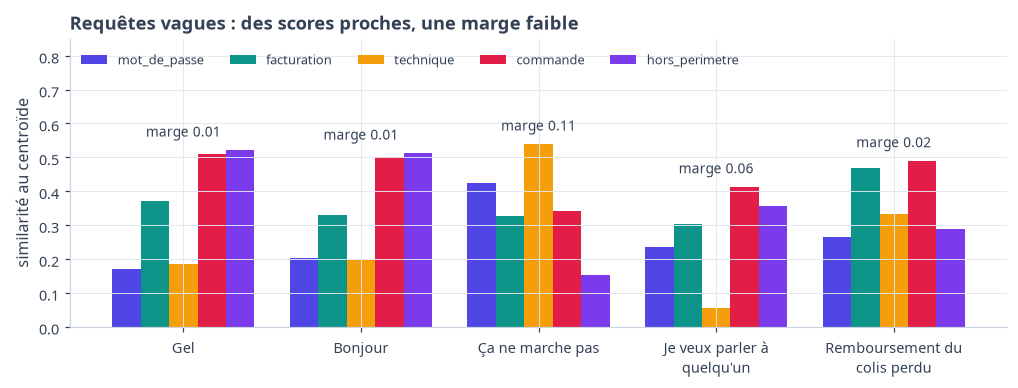

In [7]:
router = routers[("MiniLM multilingue", "centroid")]
vagues = ["Gel", "Bonjour", "Ça ne marche pas", "Je veux parler à quelqu'un", "Remboursement du colis perdu"]
S = router.scores(vagues)
fig, ax = plt.subplots(figsize=(11, 3.4))
w = 0.16
for j, (l, c) in enumerate(zip(labels, COLORS)):
    ax.bar(np.arange(len(vagues)) + (j - 2) * w, S[:, j], w, color=c, label=l)
srt = np.sort(S, axis=1)
for i in range(len(vagues)):
    ax.text(i, S[i].max() + 0.04, f"marge {srt[i, -1] - srt[i, -2]:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(len(vagues)), [textwrap.fill(v, 16) for v in vagues]); ax.set_ylabel("similarité au centroïde"); ax.set_ylim(0, 0.85)
ax.set_title("Requêtes vagues : des scores proches, une marge faible"); ax.legend(ncol=5, fontsize=8.5, loc="upper left")
plt.show()

In [8]:
strict = A.IntentRouter(embed, threshold=0.3, margin=0.05).fit(A.INTENTS_TRAIN)
pd.DataFrame({"requête": vagues + test_txt[:3],
              "sans règle de rejet": router.predict(vagues + test_txt[:3]),
              "seuil 0,30 et marge 0,05": strict.predict(vagues + test_txt[:3])})

,requête,sans règle de rejet,"seuil 0,30 et marge 0,05"
0,Gel,hors_perimetre,ambigu
1,Bonjour,hors_perimetre,ambigu
2,Ça ne marche pas,technique,technique
3,Je veux parler à quelqu'un,commande,commande
4,Remboursement du colis perdu,commande,ambigu
5,Je ne me souviens plus de mes identifiants,mot_de_passe,mot_de_passe
6,Le code de connexion est refusé à chaque fois,mot_de_passe,ambigu
7,Comment modifier mon mot de passe sur l'application ?,mot_de_passe,mot_de_passe


La règle de marge renvoie les requêtes vagues vers une demande de clarification et laisse
passer la plupart des requêtes nettes ; elle peut aussi « sur-clarifier » une requête
légitime (relisez la colonne de droite). Les seuils se règlent sur des données annotées
(exercice 10.4) : trop stricts, ils agacent l'utilisateur avec des questions inutiles.

**Combien le routeur fait-il économiser ?** Supposons qu'un appel au grand modèle coûte
$c_G$, une réponse type ou une page FAQ $\approx 0$, et qu'une fraction $f_{FAQ}$ du
trafic soit résolue sans LLM et une fraction $f_P$ envoyée à un petit modèle de coût
$c_P = c_G/10$. Le coût moyen par requête devient
$$c = c_{routeur} + f_P\,c_P + (1 - f_{FAQ} - f_P)\,c_G .$$

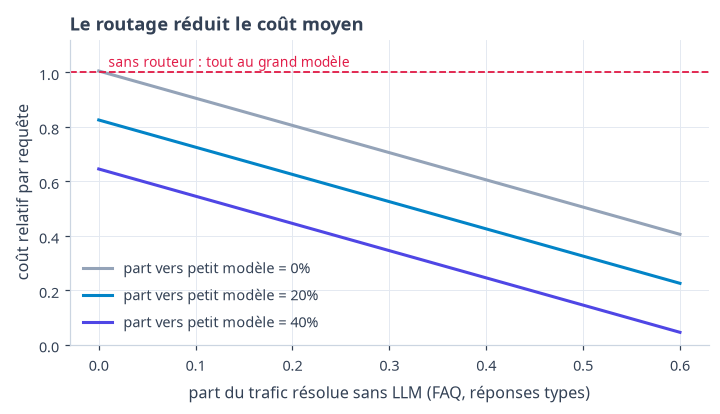

In [9]:
c_G, c_P, c_r = 1.0, 0.1, 0.005   # coûts relatifs (1 = un appel au grand modèle)
f_faq = np.linspace(0, 0.6, 61)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for f_p, c in [(0.0, GRAY), (0.2, SKY), (0.4, INDIGO)]:
    ax.plot(f_faq, c_r + f_p * c_P + (1 - f_faq - f_p).clip(0) * c_G, color=c, label=f"part vers petit modèle = {f_p:.0%}")
ax.axhline(1, color=ROSE, ls="--", lw=1.2); ax.text(0.01, 1.02, "sans routeur : tout au grand modèle", color=ROSE, fontsize=9)
ax.set(xlabel="part du trafic résolue sans LLM (FAQ, réponses types)", ylabel="coût relatif par requête",
       title="Le routage réduit le coût moyen", ylim=(0, 1.12))
ax.legend(); plt.show()

Le livre signale deux autres usages : le **prédicteur de prochaine action** pour un agent
(interpréteur de code ou recherche web ?) et le routage selon la **taille du contexte**
(une requête de 1 000 tokens qui ramène 8 000 tokens de recherche web ne tient plus dans un
modèle à 4K : on tronque, ou on la route vers un modèle à plus longue fenêtre). Le routage a
généralement lieu **avant** la recherche (la requête est-elle dans le périmètre ? a-t-elle
besoin de recherche ?), d'où le motif courant routage -> recherche -> génération -> notation.

Un routeur peut aussi se tromper, et chaque erreur a un prix différent : envoyer une
question de livraison à un conseiller humain coûte cher, envoyer un litige de facturation à
un chatbot frustre le client.

> **À retenir.** Un routeur est un petit classifieur d'intention, rapide et bon marché
> (embeddings + quelques exemples suffisent) ; il spécialise, économise, filtre le hors
> périmètre et doit savoir demander une clarification.

## 2. Étape 3b : la passerelle de modèles (section *Gateway*)

**Le problème.** Dès qu'on utilise plusieurs modèles (API de plusieurs fournisseurs,
modèles auto-hébergés), chaque application doit gérer des SDK différents, des clés d'API,
des pannes, des quotas. Une **passerelle** est une couche intermédiaire qui offre une
**interface unifiée** et centralise : contrôle d'accès (les clés ne quittent pas la
passerelle), suivi et plafonnement des coûts, politiques de **repli** en cas de panne ou de
limite de débit, équilibrage de charge, journalisation, parfois cache et garde-fous.

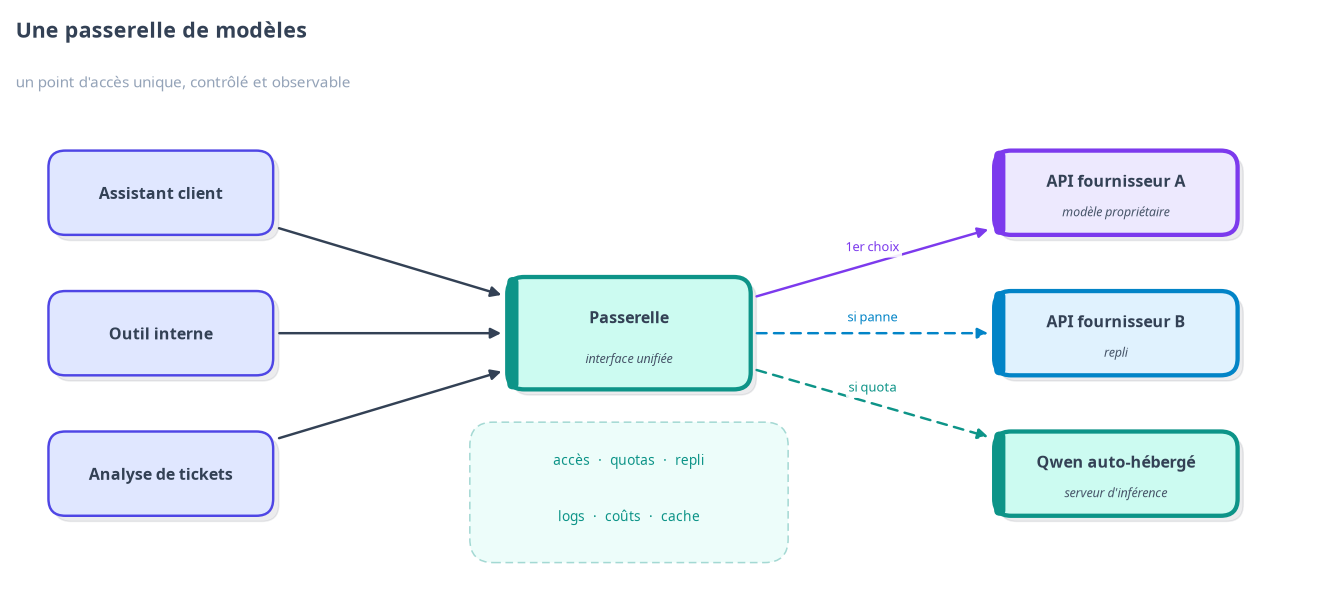

In [10]:
d = Diagram(14, 5.2, title="Une passerelle de modèles", subtitle="un point d'accès unique, contrôlé et observable")
for i, (n, t) in enumerate([("a1", "Assistant client"), ("a2", "Outil interne"), ("a3", "Analyse de tickets")]):
    d.box(n, 1.6, 4.2 - 1.5 * i, t, color=INDIGO, w=2.4)
d.box("gw", 6.6, 2.7, "Passerelle", sub="interface unifiée", color=TEAL, kind="model", w=2.6, h=1.2)
d.group(4.9, 0.25, 8.3, 1.75, None, color=TEAL)
d.note(6.6, 1.35, "accès  ·  quotas  ·  repli", color=TEAL, style="normal", fontsize=9)
d.note(6.6, 0.75, "logs  ·  coûts  ·  cache", color=TEAL, style="normal", fontsize=9)
for i, (n, t, s) in enumerate([("p1", "API fournisseur A", "modèle propriétaire"), ("p2", "API fournisseur B", "repli"),
                               ("p3", "Qwen auto-hébergé", "serveur d'inférence")]):
    d.box(n, 11.8, 4.2 - 1.5 * i, t, sub=s, color=[VIOLET, SKY, TEAL][i], kind="model", w=2.6)
for n in ["a1", "a2", "a3"]:
    d.arrow(n, "gw")
d.arrow("gw", "p1", "1er choix", color=VIOLET)
d.arrow("gw", "p2", "si panne", color=SKY, style="dashed")
d.arrow("gw", "p3", "si quota", color=TEAL, style="dashed")
d.show()

Notre `ModelGateway` implémente ces fonctions en quelques dizaines de lignes. Déclarons
deux fournisseurs : une « API externe » simulée (en réalité Qwen, enveloppé dans un
injecteur de pannes qui renvoie une erreur 503 dans 40 % des cas) et le Qwen
« auto-hébergé » comme repli. Les prix sont des ordres de grandeur en dollars par million
de tokens.

In [11]:
api = A.Provider("api-externe", qwen, price_in=0.5, price_out=1.5, fail_rate=0.4, base_ms=400, ms_per_token=15, seed=3)
local = A.Provider("qwen-local", qwen, price_in=0.05, price_out=0.05, base_ms=250, ms_per_token=25)
gw = A.ModelGateway([api, local], rate_limit=(5, 1.0))
qs = ["Donne un synonyme de rapide.", "Traduis 'merci' en anglais.", "Combien font 12 x 3 ?",
      "Cite une couleur primaire.", "Donne un antonyme de chaud.", "Quelle est la capitale de l'Italie ?"]
for t, q in enumerate(qs):
    r = gw.call([{"role": "user", "content": q}], app="assistant", now=float(t))
logs = pd.DataFrame(gw.logs); logs["cout_$"] = logs["cout_$"].map("{:.1e}".format); logs

,t,app,statut,fournisseur,tentatives,latence_ms,cout_$
0,0.0,assistant,200 ok,qwen-local,2,1075.0,7.5e-07
1,1.0,assistant,200 ok,qwen-local,2,1100.0,7.5e-07
2,2.0,assistant,200 ok,api-externe,1,730.0,3.7e-05
3,3.0,assistant,200 ok,api-externe,1,1435.0,1.1e-04
4,4.0,assistant,200 ok,qwen-local,2,1050.0,7.0e-07
5,5.0,assistant,200 ok,api-externe,1,1375.0,1.0e-04


Quand l'API externe renvoie une erreur, la passerelle bascule sur le modèle local :
l'application ne voit qu'une latence un peu plus forte. Chaque appel est **journalisé**
(fournisseur, tentatives, latence, coût), matière première du monitoring (cours 3).

**Disponibilité avec repli.** Si les fournisseurs tombent en panne indépendamment, avec des
disponibilités $a_1, \dots, a_m$, la requête échoue seulement si tous échouent :
$$A = 1 - \prod_{i=1}^{m} (1 - a_i).$$
Deux fournisseurs à 99 % donnent 99,99 % : on passe de 7 h 18 min d'indisponibilité par
mois à environ 4 minutes. L'hypothèse d'indépendance est optimiste (une panne de
l'hébergeur cloud peut toucher les deux). Vérifions par simulation, avec de faux modèles
instantanés pour aller vite.

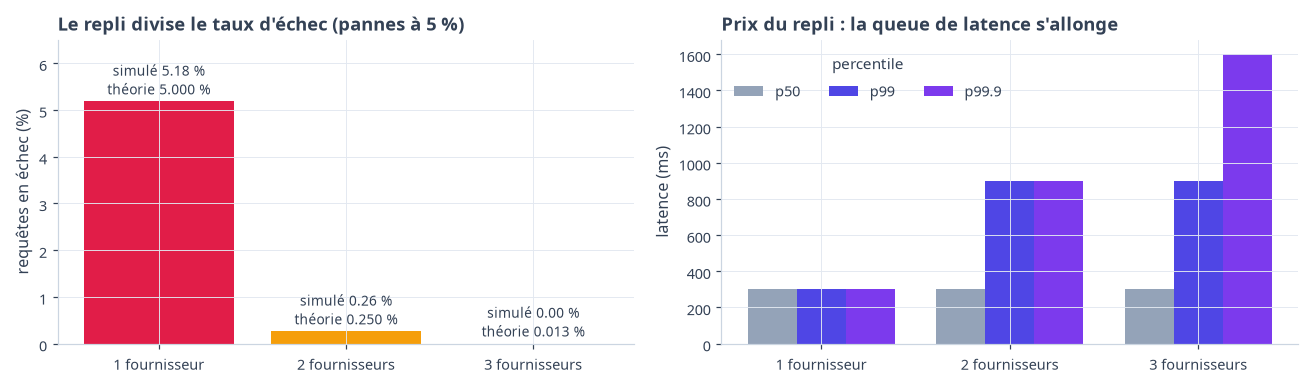

In [12]:
def simulate_availability(fail_rates, n=5000, seed=0):
    provs = [A.Provider(f"p{i}", lambda m: "ok", fail_rate=f, base_ms=300 + 100 * i, ms_per_token=0, seed=seed + i)
             for i, f in enumerate(fail_rates)]
    g = A.ModelGateway(provs)
    res = [g.call("x") for _ in range(n)]
    return np.mean([r.text is not None for r in res]), np.array([r.latency_ms for r in res if r.text])

configs = {"1 fournisseur": [0.05], "2 fournisseurs": [0.05, 0.05], "3 fournisseurs": [0.05, 0.05, 0.05]}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (name, fr) in enumerate(configs.items()):
    av, lat = simulate_availability(fr)
    theo = 1 - np.prod(fr)
    ax[0].bar(i, 100 * (1 - av), color=[ROSE, AMBER, TEAL][i])
    ax[0].text(i, 100 * (1 - av) + 0.15, f"simulé {100 * (1 - av):.2f} %\nthéorie {100 * (1 - theo):.3f} %", ha="center", fontsize=9)
    for j, q in enumerate([50, 99, 99.9]):
        ax[1].bar(i + (j - 1) * 0.26, np.percentile(lat, q), 0.26, color=[GRAY, INDIGO, VIOLET][j],
                  label=f"p{q:g}" if i == 0 else None)
ax[0].set_xticks(range(3), list(configs)); ax[0].set_ylim(0, 6.5)
ax[0].set(ylabel="requêtes en échec (%)", title="Le repli divise le taux d'échec (pannes à 5 %)")
ax[1].set_xticks(range(3), list(configs))
ax[1].set(ylabel="latence (ms)", title="Prix du repli : la queue de latence s'allonge")
ax[1].legend(title="percentile", ncol=3); plt.tight_layout(); plt.show()

Le repli fait chuter le taux d'échec, mais les requêtes rattrapées paient la tentative
ratée et l'attente avant de basculer : la distribution des latences gagne une **queue**.

**Limitation de débit.** La passerelle protège aussi le budget (et les quotas du
fournisseur) avec un **seau à jetons** : un seau de capacité $B$ se remplit à $r$ jetons par
seconde, chaque requête consomme un jeton, et une requête sans jeton reçoit une erreur 429.
Le débit soutenu est $r$ requêtes/s, mais des rafales jusqu'à $B$ requêtes passent.

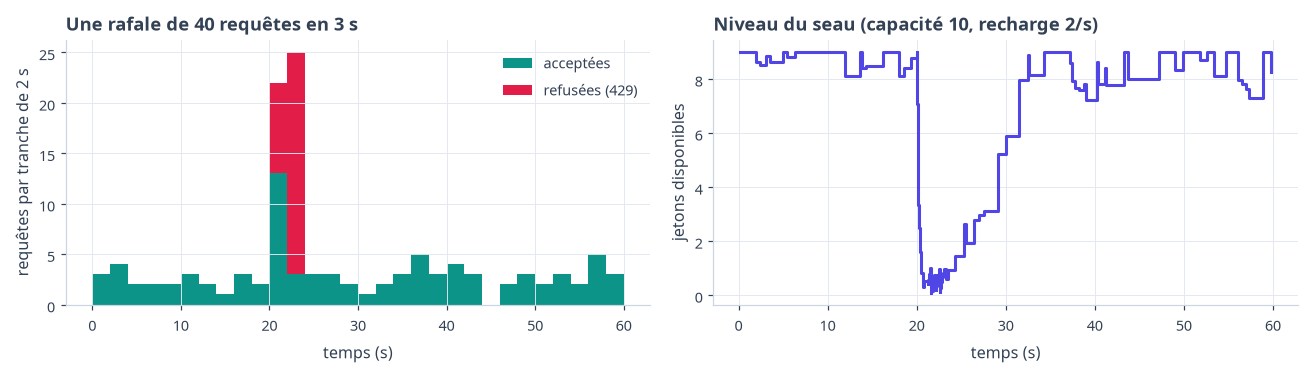

31 requêtes refusées sur 120


In [13]:
bucket = A.TokenBucket(capacity=10, rate=2.0)
t_arr = np.sort(np.concatenate([rng.uniform(0, 60, 80), rng.uniform(20, 23, 40)]))   # trafic + rafale à t = 20 s
ok, level = [], []
for t in t_arr:
    ok.append(bucket.allow(t)); level.append(bucket.tokens)
ok = np.array(ok)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.arange(0, 61, 2)
ax[0].hist([t_arr[ok], t_arr[~ok]], bins=bins, stacked=True, color=[TEAL, ROSE], label=["acceptées", "refusées (429)"])
ax[0].set(xlabel="temps (s)", ylabel="requêtes par tranche de 2 s", title="Une rafale de 40 requêtes en 3 s")
ax[0].legend()
ax[1].step(t_arr, level, color=INDIGO, where="post")
ax[1].set(xlabel="temps (s)", ylabel="jetons disponibles", title="Niveau du seau (capacité 10, recharge 2/s)")
plt.tight_layout(); plt.show()
print(f"{(~ok).sum()} requêtes refusées sur {len(ok)}")

Enfin, le **contrôle d'accès** : on déclare quels modèles chaque application peut utiliser.

In [14]:
gw_acl = A.ModelGateway([api, local], access={"stagiaire": {"qwen-local"}, "assistant": {"api-externe", "qwen-local"}})
for app_name in ["stagiaire", "inconnu"]:
    r = gw_acl.call("Bonjour", app=app_name)
    print(f"{app_name:10s} -> statut {r.status}, fournisseur {r.provider}")

stagiaire  -> statut 200 ok, fournisseur qwen-local
inconnu    -> statut 403 accès refusé, fournisseur None


> **À retenir.** La passerelle unifie l'accès aux modèles, garde les clés, plafonne les
> coûts, journalise tout et rend l'application résiliente par le repli :
> $A = 1 - \prod (1 - a_i)$, au prix d'une queue de latence.

## 3. Étape 4a : le cache exact (section *Exact caching*)

Les caches réduisent la latence et le coût. Le chapitre 9 a traité les caches
d'**inférence** (cache KV, cache de prompt) ; ici il s'agit des caches **système**. Avec
un **cache exact**, on ne réutilise une réponse que si la requête est **identique** (après
normalisation : minuscules, ponctuation). C'est utile pour les requêtes répétées (résumés de
fiches produits, recherche vectorielle d'une même requête) et pour les étapes coûteuses
(chaîne de raisonnement, SQL, recherche web).

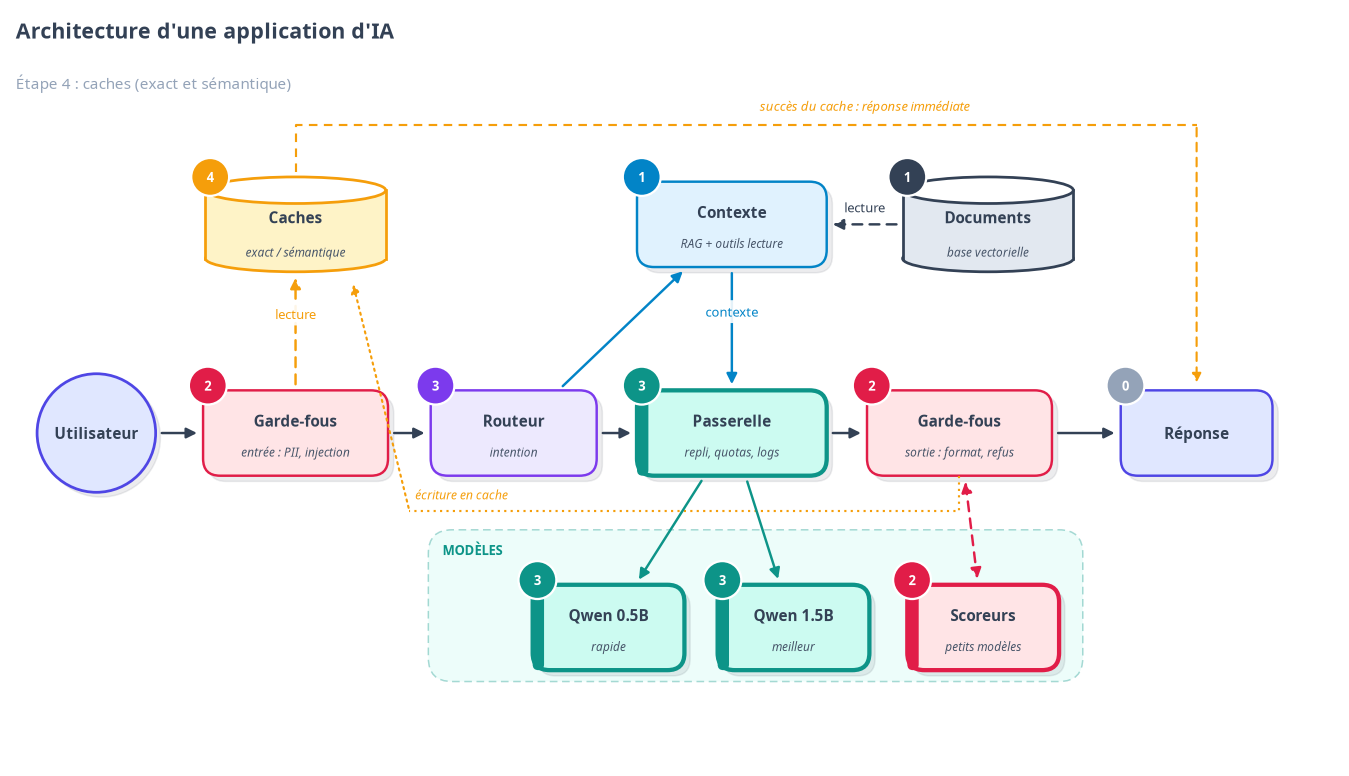

In [15]:
A.architecture_diagram(4);

**Le cache marche-t-il ?** Tout dépend de la distribution des requêtes. Le trafic réel
suit souvent une **loi de Zipf** : la $i$-ème requête la plus fréquente a une probabilité
$p_i \propto 1/i^s$. Si le cache contenait en permanence les $C$ requêtes les plus
fréquentes parmi $N$, son taux de succès serait
$$h(C) = \frac{\sum_{i=1}^{C} i^{-s}}{\sum_{i=1}^{N} i^{-s}} = \frac{H_{C,s}}{H_{N,s}},$$
où $H_{n,s}$ est le nombre harmonique généralisé. Pour $s = 1$, $H_{n,1} \approx \ln n + 0{,}577$ :
avec $N = 10\,000$ requêtes distinctes, un cache de 100 entrées (1 %) capte déjà environ la
moitié du trafic. Les politiques réelles (LRU, FIFO) ne connaissent pas les fréquences :
comparons-les à cette borne.

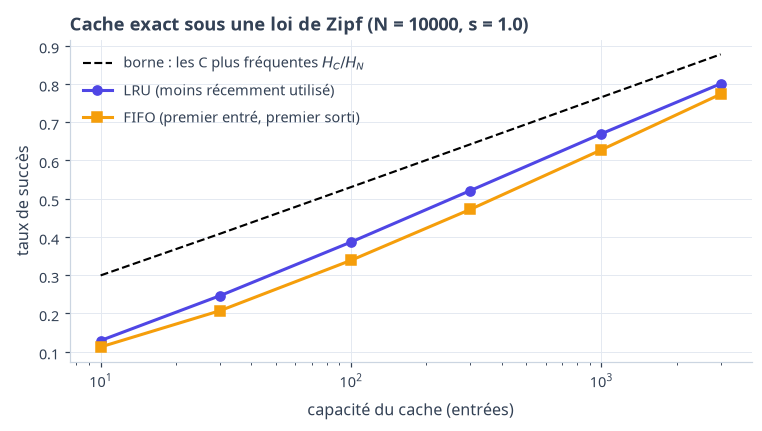

In [16]:
N, s_zipf, n_req = 10_000, 1.0, 40_000
p = 1 / np.arange(1, N + 1) ** s_zipf; p /= p.sum()
stream = rng.choice(N, size=n_req, p=p)
caps = [10, 30, 100, 300, 1000, 3000]
res = {"LRU": [], "FIFO": []}
for cap in caps:
    for pol in res:
        c = A.ExactCache(capacity=cap, policy=pol.lower(), normalize_key=False)
        for q in stream:
            if c.get(str(q)) is None:
                c.put(str(q), 1)
        res[pol].append(c.hit_rate)
H = np.cumsum(1 / np.arange(1, N + 1) ** s_zipf)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(caps, [H[c - 1] / H[-1] for c in caps], "k--", lw=1.4, label="borne : les C plus fréquentes $H_{C}/H_{N}$")
ax.plot(caps, res["LRU"], "o-", color=INDIGO, label="LRU (moins récemment utilisé)")
ax.plot(caps, res["FIFO"], "s-", color=AMBER, label="FIFO (premier entré, premier sorti)")
ax.set(xscale="log", xlabel="capacité du cache (entrées)", ylabel="taux de succès",
       title=f"Cache exact sous une loi de Zipf (N = {N}, s = {s_zipf})")
ax.legend(); plt.show()

LRU fait mieux que FIFO car il garde ce qui sert souvent, mais reste sous la borne
(il gaspille de la place pour des requêtes rares récentes) ; LFU (moins fréquemment
utilisé) s'en approcherait sur un trafic stable. Les courbes sont presque des droites en
échelle logarithmique : chaque **décuplement** de la capacité ajoute à peu près le même
nombre de points de taux de succès (environ 0,25 ici). C'est un rendement décroissant :
passer de 100 à 1 000 entrées rapporte autant que passer de 10 à 100.

**Que ne pas mettre en cache ?** Les requêtes **personnelles** (« où en est ma
commande ? ») et **datées** (« quel temps fait-il ? »). L'encadré du livre raconte une fuite
typique : une question d'apparence générique (« quelle est la politique de retour ? ») dont
la réponse dépend du statut de l'utilisateur X est mise en cache, puis servie à
l'utilisateur Y. Beaucoup d'équipes entraînent un classifieur « à mettre en cache ou non » ;
notre `is_cacheable` est une version à base de règles (exercice 10.7).

In [17]:
exemples = ["Quels moyens de paiement acceptez-vous ?", "Où en est ma commande 1042 ?",
            "Quel temps fait-il aujourd'hui à Lyon ?", "Quelle est la durée de garantie d'un téléviseur ?",
            "Quelle est la politique de retour pour les membres premium ?"]
pd.DataFrame({"requête": exemples, "mise en cache autorisée": [A.is_cacheable(e) for e in exemples]})

,requête,mise en cache autorisée
0,Quels moyens de paiement acceptez-vous ?,True
1,Où en est ma commande 1042 ?,False
2,Quel temps fait-il aujourd'hui à Lyon ?,False
3,Quelle est la durée de garantie d'un téléviseur ?,True
4,Quelle est la politique de retour pour les membres premium ?,True


La dernière ligne montre la limite des règles : la requête paraît générique, mais si la
réponse est construite à partir du profil de l'utilisateur, elle ne doit pas être
partagée. La solution robuste est d'inclure dans la clé de cache tout ce dont dépend la
réponse (par exemple le segment de l'utilisateur).

> **À retenir.** Le taux de succès d'un cache exact dépend de la concentration du trafic
> (Zipf) et de la politique d'éviction ; ne mettez jamais en cache une réponse qui dépend
> de l'utilisateur sans l'inclure dans la clé.

## 4. Étape 4b : le cache sémantique (section *Semantic caching*)

Un **cache sémantique** réutilise une réponse si la nouvelle requête est **assez
similaire** à une requête passée : « Quelle est la capitale du Vietnam ? » et « Quelle est
la ville capitale du Vietnam ? » partagent la réponse. Algorithme : (1) calculer
l'embedding de la requête ; (2) chercher l'embedding en cache le plus proche, de similarité
$X$ ; (3) si $X \ge \tau$, renvoyer la réponse en cache, sinon calculer la réponse et
l'ajouter au cache. Le livre est réservé : le taux de succès augmente, mais **une erreur de
cache renvoie la réponse à une autre question**. Mesurons ce compromis.

Notre jeu `A.CACHE_QUERIES` contient 36 questions groupées par réponse attendue ; il
comprend des **pièges** : « délai de livraison en France » et « en Belgique » sont presque
identiques lexicalement mais n'ont pas la même réponse.

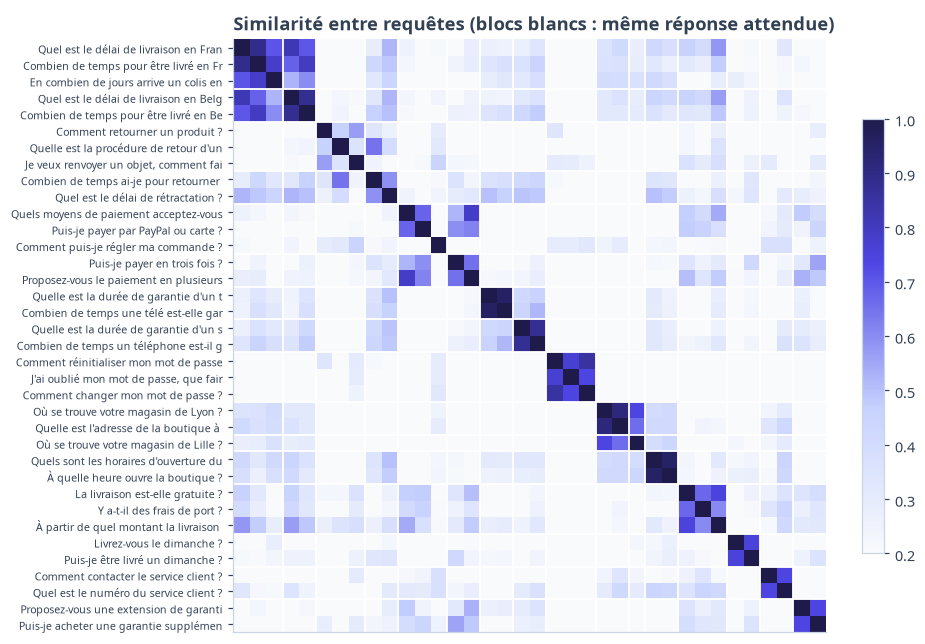

In [18]:
cq = [q for q, _ in A.CACHE_QUERIES]; cg = np.array([g for _, g in A.CACHE_QUERIES])
Ec = embed(cq)
Sc = Ec @ Ec.T
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(Sc, cmap="aie_seq", vmin=0.2, vmax=1); ax.grid(False)
bounds = [i for i in range(1, len(cg)) if cg[i] != cg[i - 1]]
for b in bounds:
    ax.axhline(b - 0.5, color="white", lw=1.2); ax.axvline(b - 0.5, color="white", lw=1.2)
ax.set_yticks(range(len(cq)), [q[:38] for q in cq], fontsize=7)
ax.set_xticks([])
ax.set_title("Similarité entre requêtes (blocs blancs : même réponse attendue)")
plt.colorbar(im, ax=ax, fraction=0.03); plt.show()

Les blocs diagonaux (paraphrases) sont foncés, mais certaines cases **hors** des blocs le
sont aussi : France/Belgique, téléviseur/smartphone, Lyon/Lille. Un seuil trop bas les
confondra. Rejouons le flux de requêtes dans un cache sémantique pour chaque seuil : la
requête $i$ interroge le cache formé des requêtes $0..i-1$. On compte les **succès** et,
parmi eux, les **erreurs** (requête trouvée d'un autre groupe).

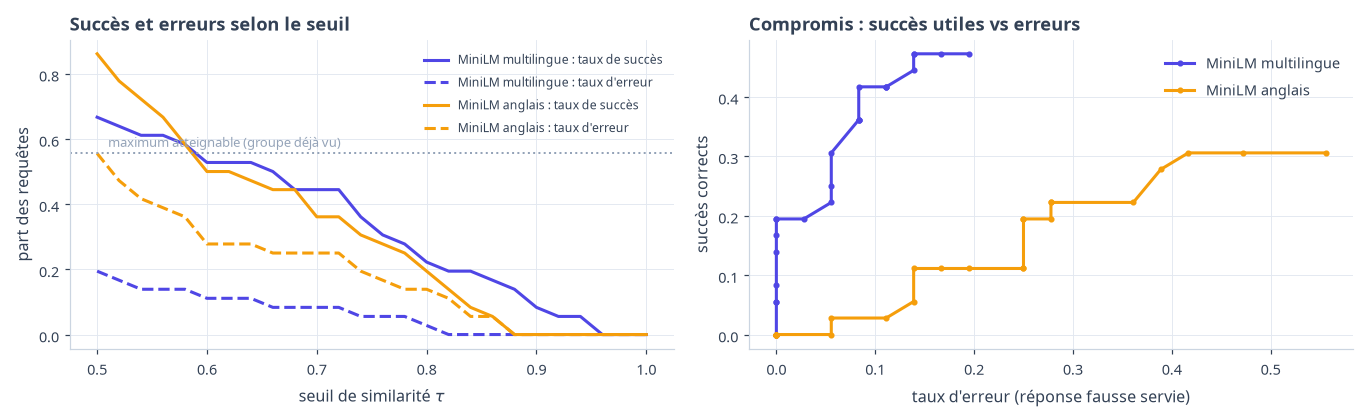

In [19]:
thr = np.linspace(0.5, 1.0, 26)
stats = {name: A.pairwise_cache_stats(f(cq), cg, thr) for name, f in
         [("MiniLM multilingue", embed), ("MiniLM anglais", embed_en)]}
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
for (name, st), c in zip(stats.items(), [INDIGO, AMBER]):
    ax[0].plot(thr, st["hit_rate"], color=c, label=f"{name} : taux de succès")
    ax[0].plot(thr, st["err_rate"], color=c, ls="--", label=f"{name} : taux d'erreur")
    ax[1].plot(st["err_rate"], st["hit_rate"] - st["err_rate"], "o-", color=c, ms=3, label=name)
ax[0].axhline(stats["MiniLM multilingue"]["oracle"], color=GRAY, ls=":", lw=1.3)
ax[0].text(0.51, stats["MiniLM multilingue"]["oracle"] + 0.02, "maximum atteignable (groupe déjà vu)", fontsize=8.5, color=GRAY)
ax[0].set(xlabel="seuil de similarité $\\tau$", ylabel="part des requêtes", title="Succès et erreurs selon le seuil")
ax[0].legend(fontsize=8)
ax[1].set(xlabel="taux d'erreur (réponse fausse servie)", ylabel="succès corrects",
          title="Compromis : succès utiles vs erreurs")
ax[1].legend(); plt.tight_layout(); plt.show()

In [20]:
st = stats["MiniLM multilingue"]
tab = pd.DataFrame({"seuil": thr, "succès": st["hit_rate"], "erreurs": st["err_rate"], "précision": st["precision"]})
tab[tab.seuil.round(2).isin([0.6, 0.7, 0.8, 0.85, 0.9, 0.95])].round(2)

,seuil,succès,erreurs,précision
5,0.6,0.53,0.11,0.79
10,0.7,0.44,0.08,0.81
15,0.8,0.22,0.03,0.88
20,0.9,0.08,0.00,1.00


Il n'existe pas de seuil « gratuit » : pour récupérer une part importante des paraphrases,
il faut accepter de servir quelques mauvaises réponses. Avec l'encodeur anglais, la courbe
est bien pire (beaucoup d'erreurs à taux de succès égal) : la qualité des embeddings est la
première condition du cache sémantique, comme le dit le livre.

**Effet sur le coût et la latence.** Notons $h$ le taux de succès, $e$ le taux d'erreur,
$c$ et $\ell$ le coût et la latence d'un appel au modèle, $c_{lk}$, $\ell_{lk}$ ceux de la
recherche dans le cache (embedding + recherche vectorielle, payés **à chaque requête**) et
$c_{err}$ le coût d'une mauvaise réponse (client mal informé, ticket supplémentaire) :
$$\bar c = c_{lk} + (1-h)\,c + e\,c_{err}, \qquad \bar\ell = \ell_{lk} + (1-h)\,\ell .$$

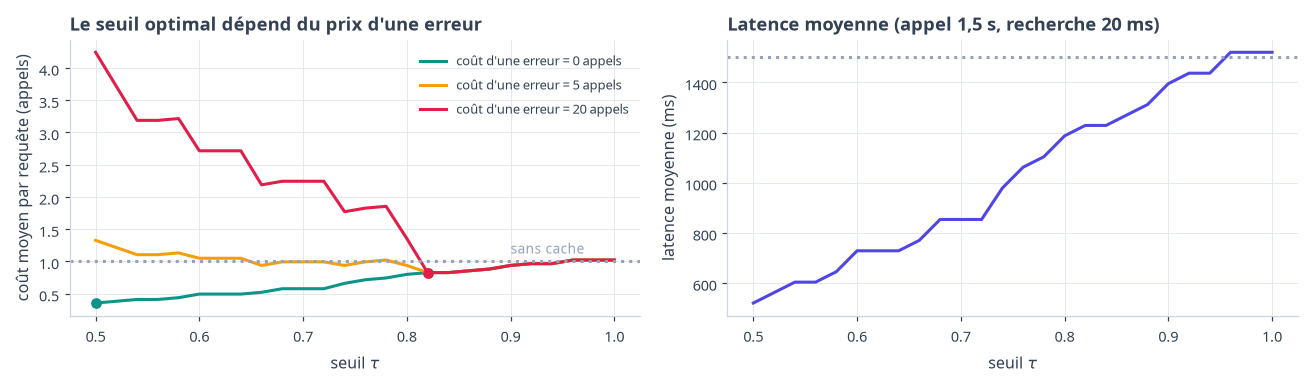

In [21]:
c_call, l_call, l_lk, c_lk = 1.0, 1500, 20, 0.02
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for c_err, col in [(0, TEAL), (5, AMBER), (20, ROSE)]:
    cost = [A.cache_economics(h, e, c_call, l_call, l_lk, c_lk, c_err)["cout"] for h, e in zip(st["hit_rate"], st["err_rate"])]
    ax[0].plot(thr, cost, color=col, label=f"coût d'une erreur = {c_err} appels")
    j = int(np.argmin(cost)); ax[0].plot(thr[j], cost[j], "o", color=col)
ax[0].axhline(c_call, color=GRAY, ls=":"); ax[0].text(0.9, c_call + 0.12, "sans cache", color=GRAY, fontsize=9)
ax[0].set(xlabel="seuil $\\tau$", ylabel="coût moyen par requête (appels)", title="Le seuil optimal dépend du prix d'une erreur")
ax[0].legend(fontsize=8.5)
lat = [A.cache_economics(h, e, c_call, l_call, l_lk)["latence"] for h, e in zip(st["hit_rate"], st["err_rate"])]
ax[1].plot(thr, lat, color=INDIGO); ax[1].axhline(l_call, color=GRAY, ls=":")
ax[1].set(xlabel="seuil $\\tau$", ylabel="latence moyenne (ms)", title="Latence moyenne (appel 1,5 s, recherche 20 ms)")
plt.tight_layout(); plt.show()

Si les erreurs ne coûtent rien, on prendrait un seuil bas ; dès qu'une mauvaise réponse a
un prix, le seuil optimal remonte et le gain fond. Sur ce petit jeu le taux de succès est
élevé par construction (beaucoup de paraphrases) ; en production, si le trafic contient
peu de reformulations, le cache sémantique peut **coûter** plus qu'il ne rapporte (la
recherche est payée à chaque requête). Mesurez avant d'adopter.

Voyons-le en action dans la mini-application (étape 4) avec deux seuils.

In [22]:
flux = ["Quel est le délai de livraison en France ?", "Combien de temps pour être livré en France ?",
        "Quel est le délai de livraison en Belgique ?", "Quels moyens de paiement acceptez-vous ?",
        "Puis-je payer par PayPal ou carte ?"]
rows = []
for tau in [0.9, 0.7]:
    app4 = A.MiniApp(qwen, step=4, embed_fn=embed, sem_threshold=tau)
    for q in flux:
        r = app4.ask(q)
        rows.append({"seuil": tau, "requête": q, "cache": r.meta.get("cache", "-"), "réponse": r.text[:70],
                     "latence (ms)": round(r.latency_ms)})
pd.DataFrame(rows)

,seuil,requête,cache,réponse,latence (ms)
0,0.9,Quel est le délai de livraison en France ?,-,Le délai de livraison en France est de 2 à 3 jours ouvrés.,726
1,0.9,Combien de temps pour être livré en France ?,-,1 à 2 jours ouvrés.,506
2,0.9,Quel est le délai de livraison en Belgique ?,-,Le délai de livraison en Belgique est de 4 à 5 jours ouvrés.,726
3,0.9,Quels moyens de paiement acceptez-vous ?,-,Votre demande concerne la facturation : je vous transfère à un conseil,41
4,0.9,Puis-je payer par PayPal ou carte ?,-,Votre demande concerne la facturation : je vous transfère à un conseil,41
5,0.7,Quel est le délai de livraison en France ?,-,Le délai de livraison en France est de 2 à 3 jours ouvrés.,726
6,0.7,Combien de temps pour être livré en France ?,sémantique (sim=0.88 avec « Quel est le délai de livraison en France ? »),Le délai de livraison en France est de 2 à 3 jours ouvrés.,26
7,0.7,Quel est le délai de livraison en Belgique ?,sémantique (sim=0.82 avec « Quel est le délai de livraison en France ? »),Le délai de livraison en France est de 2 à 3 jours ouvrés.,26
8,0.7,Quels moyens de paiement acceptez-vous ?,-,Votre demande concerne la facturation : je vous transfère à un conseil,41
9,0.7,Puis-je payer par PayPal ou carte ?,-,Votre demande concerne la facturation : je vous transfère à un conseil,41


Lisez la colonne « cache ». Avec le seuil 0,7, la paraphrase sur la France est
correctement servie par le cache, mais la question sur la **Belgique** reçoit la réponse
mise en cache pour la France (similarité d'environ 0,8) : c'est exactement l'erreur que
redoute le livre. Avec le seuil 0,9, aucune de ces paraphrases n'est assez proche : le
modèle est rappelé à chaque fois (et, détail instructif, il peut répondre différemment à
deux formulations d'une même question : un cache aurait ici amélioré la **cohérence**).
Les requêtes servies par le cache répondent en quelques dizaines de millisecondes au lieu
de plusieurs centaines.

> **À retenir.** Le cache sémantique échange des erreurs contre des économies : il exige
> de bons embeddings, un seuil réglé sur des données, et un trafic riche en reformulations.

## 5. Étape 5 : les motifs agentiques (section *Step 5. Add Agent Patterns*)

Jusqu'ici, chaque requête suit un flux **séquentiel**. Les motifs agentiques du chapitre 6
ajoutent **boucles**, **parallélisme** et **branchements conditionnels**. Exemple du livre :
après avoir généré une réponse, le système constate qu'elle est incomplète, relance une
recherche, et repasse la réponse et le nouveau contexte au modèle : c'est la flèche de
retour du diagramme.

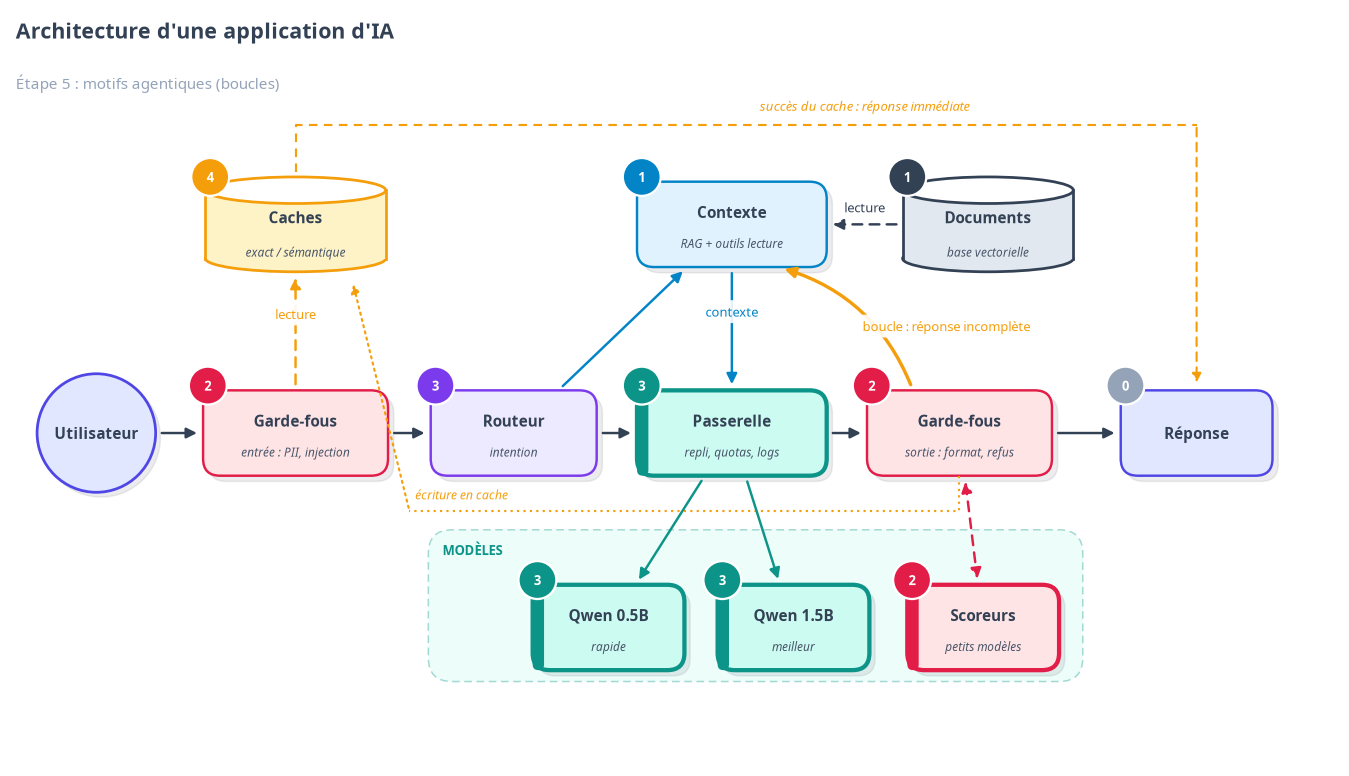

In [23]:
A.architecture_diagram(5);

Notre mini-application implémente une boucle simple d'**auto-vérification** : la question
est découpée en propositions ; si une proposition est mal couverte par le contexte
(similarité maximale < 0,5), ou si le modèle dit ne pas savoir, le système lance une
recherche **ciblée** sur cette proposition et régénère. Comparons les étapes 4 et 5 sur une
question à deux volets, avec un contexte volontairement limité à $k = 1$ document.

In [24]:
q2 = "Je veux renvoyer ma télé : combien de temps ai-je pour la retourner, et combien de temps dure sa garantie ?"
r4 = A.MiniApp(qwen, step=4, embed_fn=embed, k=1).ask(q2)
r5 = A.MiniApp(qwen, step=5, embed_fn=embed, k=1).ask(q2)
pd.DataFrame({"étape": [4, 5], "réponse": [r4.text, r5.text],
              "documents utilisés": [len(r4.meta["contexte"]), len(r5.meta["contexte"])],
              "boucle déclenchée par": ["-", "; ".join(r5.meta.get("boucle", []))],
              "latence (ms)": [round(r4.latency_ms), round(r5.latency_ms)]})

,étape,réponse,documents utilisés,boucle déclenchée par,latence (ms)
0,4,"Pour la garantie, vous avez 2 ans, puis 3 ans supplémentaires. Pour la retour, il faud...",1,-,865
1,5,"Pour votre télévision, vous avez 30 jours pour la retourner. Sa garantie est de 2 ans ...",2,combien de temps ai-je pour la retourner,1805


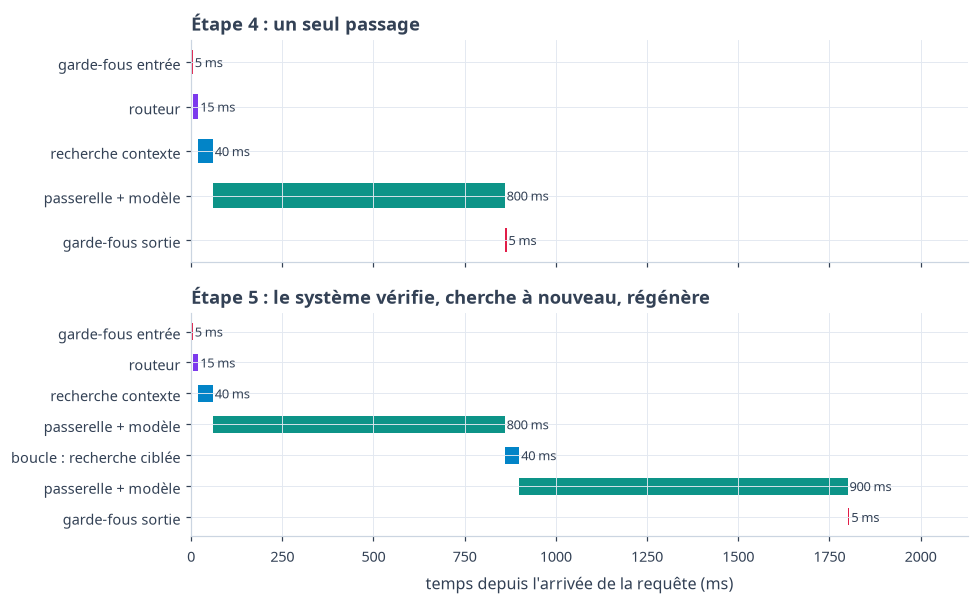

In [25]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
A.plot_trace(r4.trace, ax=ax[0], title="Étape 4 : un seul passage")
A.plot_trace(r5.trace, ax=ax[1], title="Étape 5 : le système vérifie, cherche à nouveau, régénère")
ax[0].set_xlabel(""); ax[1].set_xlim(0, max(r5.latency_ms, r4.latency_ms) * 1.18)
plt.tight_layout(); plt.show()

Sans boucle, le modèle n'a que le document sur la garantie et **invente** le délai de
retour ; avec la boucle, la proposition « combien de temps ai-je pour la retourner » est
détectée comme non couverte, le document sur les retours est ajouté et la réponse devient
correcte sur ce point (relisez-la : la formulation reste celle d'un petit modèle). Le prix :
la latence double presque.

**Combien coûte une boucle ?** Si chaque itération conclut avec probabilité $p$ et qu'on
plafonne à $n$ itérations, le nombre moyen d'appels est (comme pour la relance du cours 1)
$\frac{1-(1-p)^n}{p}$ ; la latence et le coût croissent d'autant, et chaque itération est
une occasion supplémentaire d'erreur. D'où l'importance du plafond et de la trace.

> **À retenir.** Les boucles permettent de compléter ou corriger une réponse ; elles
> multiplient latence et coût et rendent le système plus difficile à déboguer.

## 6. Étape 6 : les actions d'écriture (section *Step 5. Add Agent Patterns*)

Les sorties du modèle peuvent déclencher des **actions d'écriture** : envoyer un email,
passer ou annuler une commande, initier un virement. Elles rendent le système beaucoup plus
capable... et beaucoup plus risqué (chapitre 6). Le livre recommande la plus grande
prudence ; un principe courant est la **confirmation humaine** pour toute action
irréversible, plus des vérifications déterministes (l'action est-elle permise dans l'état
actuel ?).

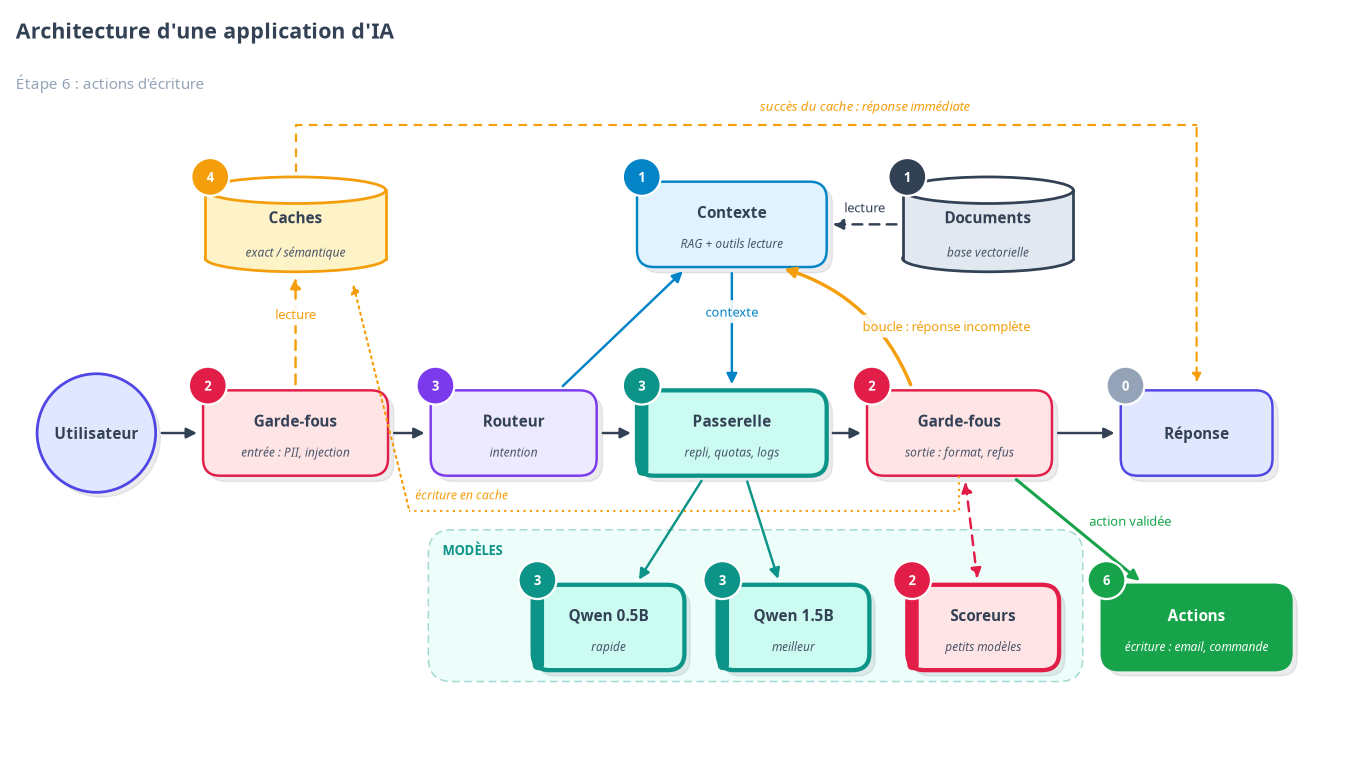

In [26]:
A.architecture_diagram(6);

In [27]:
app6 = A.MiniApp(qwen, step=6, embed_fn=embed)
dialogue = [("Je veux annuler ma commande 1042", False), ("Je veux annuler ma commande 1042", True),
            ("Annulez la commande 1043 svp", False), ("Annule la commande 9999", False)]
rows = []
for q, conf in dialogue:
    r = app6.ask(q, user="client_42", confirm=conf)
    rows.append({"requête": q, "confirmé": conf, "action": r.meta.get("action", "-"), "réponse": r.text})
display(pd.DataFrame(rows))
print("Journal des actions :", app6.actions_log)
print("État des commandes  :", app6.orders)

,requête,confirmé,action,réponse
0,Je veux annuler ma commande 1042,False,annuler_commande(1042),Je peux annuler la commande 1042. Confirmez-vous ? (action irréversible)
1,Je veux annuler ma commande 1042,True,annuler_commande(1042),C'est fait : la commande 1042 est annulée.
2,Annulez la commande 1043 svp,False,annuler_commande(1043),"La commande 1043 est déjà expédiée : annulation impossible, mais vous pourrez la retou..."
3,Annule la commande 9999,False,-,Votre demande concerne la facturation : je vous transfère à un conseiller humain.


Journal des actions : [{'utilisateur': 'client_42', 'action': 'annuler_commande', 'commande': '1042'}]
État des commandes  : {'1042': 'annulée', '1043': 'expédiée'}


L'action n'est exécutée qu'après confirmation, et les règles métier (commande déjà
expédiée, commande inconnue) sont vérifiées par du code, pas par le modèle. La dernière
ligne montre aussi un **défaut du routeur** : selon la formulation, une demande
d'annulation peut être classée dans une autre intention (ici, si elle part vers la
facturation, elle est transférée à un humain au lieu d'atteindre le code d'annulation).
C'est un échec sans danger, mais il rappelle qu'une chaîne de composants accumule les
erreurs de chacun. Chaque action
est **journalisée** avec l'utilisateur qui l'a demandée.

**Quantifier le risque.** Si le système exécute $V$ actions par jour, qu'une fraction $p$
est erronée (mauvaise intention, mauvais identifiant) et que chaque erreur coûte $I$,
la perte attendue est $V \cdot p \cdot I$. Une confirmation qui fait rattraper une
proportion $\rho$ des erreurs la ramène à $V p (1-\rho) I$, au prix d'une friction pour
l'utilisateur.

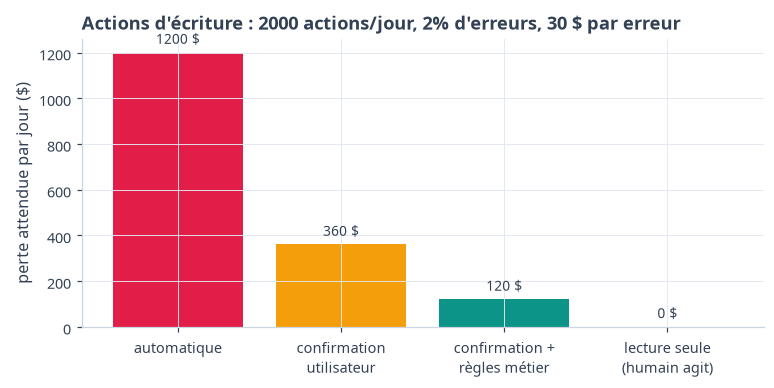

In [28]:
V, p_err, I = 2000, 0.02, 30.0
politiques = {"automatique": 0.0, "confirmation\nutilisateur": 0.7, "confirmation +\nrègles métier": 0.9,
              "lecture seule\n(humain agit)": 1.0}
pertes = [V * p_err * (1 - rho) * I for rho in politiques.values()]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(list(politiques), pertes, color=[ROSE, AMBER, TEAL, GRAY])
annotate_bars(ax, "{:.0f} $")
ax.set(ylabel="perte attendue par jour ($)", title=f"Actions d'écriture : {V} actions/jour, {p_err:.0%} d'erreurs, {I:.0f} $ par erreur")
plt.show()

Le système est maintenant complet... et complexe : sept composants, autant de points de
défaillance. Le cours 3 montre comment le rendre **observable**.

> **À retenir.** Les actions d'écriture transforment l'assistant en agent : confirmation
> humaine, règles métier déterministes et journalisation sont indispensables.

## Synthèse

- **Routeur** : un classifieur d'intention par embeddings (centroïdes ou $k$ plus proches
  voisins) oriente chaque requête vers la solution adaptée, filtre le hors périmètre et
  demande une clarification si la marge est faible. La qualité de l'encodeur est décisive.
- **Passerelle** : interface unifiée, contrôle d'accès, quotas (seau à jetons), repli
  ($A = 1 - \prod(1-a_i)$) et journalisation.
- **Cache exact** : efficace si le trafic est concentré (Zipf) ; attention aux réponses
  personnelles (fuites).
- **Cache sémantique** : compromis succès / erreurs réglé par le seuil ; rentable seulement
  avec de bons embeddings et beaucoup de reformulations.
- **Motifs agentiques** et **actions d'écriture** : plus de capacités, plus de latence, plus
  de risques ; plafonner, confirmer, journaliser.

Liens : chapitre 6 (RAG, agents), chapitre 9 (caches d'inférence, serveurs), chapitre 5
(sécurité). Suite : cours 3 (observabilité et orchestration).

In [29]:
llm.free_gpu()